## Expert System  Course Project
### Data Science and AI Department
#### Student name : Haneen S Awad
##### Student ID : 220212135
##### Project: Expert System for Post-War Building Assessment and Rehabilitation



In [ ]:
pip install scikit-fuzzy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 920.8/920.8 kB 22.2 MB/s eta 0:00:00


Crack Width: 5, Water Damage: 6, Damage Grade: 4.6231884057971016
Crack Width: 15, Water Damage: 18, Damage Grade: 1.7037037037037035


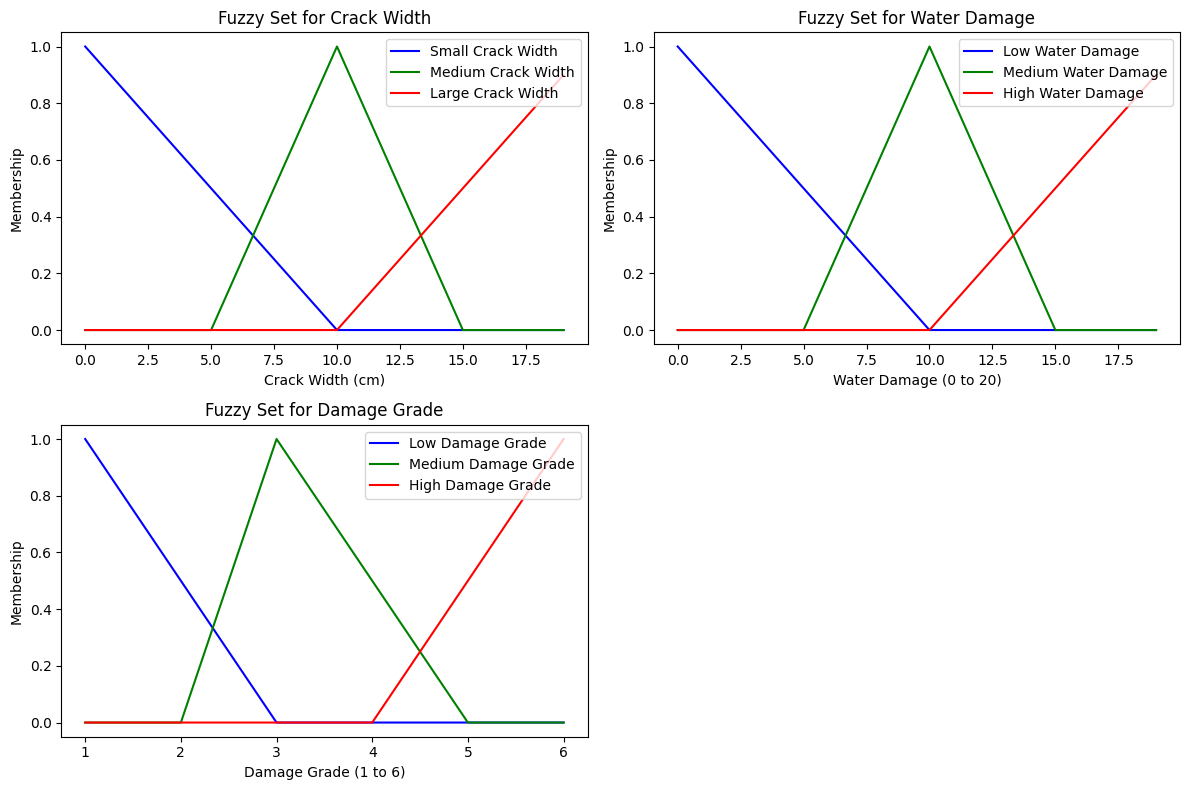

Backward chaining failed for: Grade 3: Substantial Damage.


In [ ]:
import numpy as np
import skfuzzy as fuzz
import matplotlib.pyplot as plt
ن
class DamageAssessment:
    def __init__(self):
        self.rules = []
        self.knowledge_base = {}
        self.fuzzy_inputs = {}
        self.fuzzy_outputs = {}

        # Define fuzzy variables
        self.define_fuzzy_variables()

    def define_fuzzy_variables(self):
        # Define input variables with adjusted ranges
        self.crack_width = np.arange(0, 20, 1)  # Adjusted range for crack width (0 to 20 cm)
        self.water_damage = np.arange(0, 20, 1)  # Adjusted range for water damage (0 to 20)

        # Membership functions for crack width
        self.crack_width_small = fuzz.trimf(self.crack_width, [0, 0, 10])  # Adjusted to 10
        self.crack_width_medium = fuzz.trimf(self.crack_width, [5, 10, 15])  # Adjusted the range for medium
        self.crack_width_large = fuzz.trimf(self.crack_width, [10, 20, 20])  # Adjusted to 20

        # Membership functions for water damage
        self.water_damage_low = fuzz.trimf(self.water_damage, [0, 0, 10])  # Adjusted to 10
        self.water_damage_medium = fuzz.trimf(self.water_damage, [5, 10, 15])  # Adjusted the range for medium
        self.water_damage_high = fuzz.trimf(self.water_damage, [10, 20, 20])  # Adjusted to 20

        # Output variable with updated damage grades
        self.damage_grade = np.arange(1, 7, 1)  # Adjusted damage grades from 1 to 6
        self.damage_grade_low = fuzz.trimf(self.damage_grade, [1, 1, 3])  # No change
        self.damage_grade_medium = fuzz.trimf(self.damage_grade, [2, 3, 5])  # Adjusted for medium grade
        self.damage_grade_high = fuzz.trimf(self.damage_grade, [4, 6, 6])  # Adjusted for high grade

    def add_rule(self, condition, outcome, recommendation):
        self.rules.append({'condition': condition, 'outcome': outcome, 'recommendation': recommendation})

    def assess(self, observations):
        for rule in self.rules:
            if rule['condition'](observations):
                return rule['outcome'], rule['recommendation']
        return "No assessment available", ""

    def forward_chaining(self, observations):
        results = []
        for rule in self.rules:
            if rule['condition'](observations):
                results.append(rule)
        return results

    def backward_chaining(self, goal):
        for rule in self.rules:
            if rule['outcome'] == goal:
                return rule['condition'](self.knowledge_base)
        return False

    def fuzzy_assessment(self, crack_width_value, water_damage_value):
        # Fuzzification
        crack_width_level_small = fuzz.interp_membership(self.crack_width, self.crack_width_small, crack_width_value)
        crack_width_level_medium = fuzz.interp_membership(self.crack_width, self.crack_width_medium, crack_width_value)
        crack_width_level_large = fuzz.interp_membership(self.crack_width, self.crack_width_large, crack_width_value)

        water_damage_level_low = fuzz.interp_membership(self.water_damage, self.water_damage_low, water_damage_value)
        water_damage_level_medium = fuzz.interp_membership(self.water_damage, self.water_damage_medium, water_damage_value)
        water_damage_level_high = fuzz.interp_membership(self.water_damage, self.water_damage_high, water_damage_value)

        # Rule evaluation
        active_rule1 = np.fmax(crack_width_level_large, water_damage_level_high)
        active_rule2 = np.fmax(crack_width_level_medium, water_damage_level_medium)
        active_rule3 = np.fmax(crack_width_level_small, water_damage_level_low)

        # Create output membership
        damage_grade_level_low = np.fmin(active_rule1, self.damage_grade_low)
        damage_grade_level_medium = np.fmin(active_rule2, self.damage_grade_medium)
        damage_grade_level_high = np.fmin(active_rule3, self.damage_grade_high)

        # Defuzzification
        damage_grade_combined = np.fmax(damage_grade_level_low, np.fmax(damage_grade_level_medium, damage_grade_level_high))
        damage_grade_output = fuzz.defuzz(self.damage_grade, damage_grade_combined, 'centroid')

        return damage_grade_output

    def visualize_fuzzy_sets(self):
        # Visualize fuzzy sets for crack width
        plt.figure(figsize=(12, 8))

        # Crack Width
        plt.subplot(2, 2, 1)
        plt.plot(self.crack_width, self.crack_width_small, 'b', label='Small Crack Width')
        plt.plot(self.crack_width, self.crack_width_medium, 'g', label='Medium Crack Width')
        plt.plot(self.crack_width, self.crack_width_large, 'r', label='Large Crack Width')
        plt.title('Fuzzy Set for Crack Width')
        plt.xlabel('Crack Width (cm)')
        plt.ylabel('Membership')
        plt.legend()

        # Water Damage
        plt.subplot(2, 2, 2)
        plt.plot(self.water_damage, self.water_damage_low, 'b', label='Low Water Damage')
        plt.plot(self.water_damage, self.water_damage_medium, 'g', label='Medium Water Damage')
        plt.plot(self.water_damage, self.water_damage_high, 'r', label='High Water Damage')
        plt.title('Fuzzy Set for Water Damage')
        plt.xlabel('Water Damage (0 to 20)')
        plt.ylabel('Membership')
        plt.legend()

        # Damage Grade
        plt.subplot(2, 2, 3)
        plt.plot(self.damage_grade, self.damage_grade_low, 'b', label='Low Damage Grade')
        plt.plot(self.damage_grade, self.damage_grade_medium, 'g', label='Medium Damage Grade')
        plt.plot(self.damage_grade, self.damage_grade_high, 'r', label='High Damage Grade')
        plt.title('Fuzzy Set for Damage Grade')
        plt.xlabel('Damage Grade (1 to 6)')
        plt.ylabel('Membership')
        plt.legend()

        plt.tight_layout()
        plt.show()

# Fuzzy logic functions (conditions)
def cracks_in_walls(observations):
    return 'cracks in walls' in observations

def large_cracks_in_load_bearing(observations):
    return 'large cracks in load-bearing walls' in observations

def visible_water_damage(observations):
    return 'water damage' in observations

def signs_of_bowing(observations):
    return 'bowing walls' in observations

def foundation_issues(observations):
    return 'foundation issues' in observations

def sagging_roof(observations):
    return 'sagging roof' in observations

def peeling_paint(observations):
    return 'peeling paint' in observations

def cracks_in_foundation(observations):
    return 'cracks in foundation' in observations

def missing_roof_tiles(observations):
    return 'missing roof tiles' in observations

def damp_walls(observations):
    return 'damp walls' in observations

def mold_growth(observations):
    return 'mold growth' in observations

def structural_damage(observations):
    return 'structural damage' in observations

def rust_on_beams(observations):
    return 'rust on beams' in observations

def sagging_walls(observations):
    return 'sagging walls' in observations

def broken_windows(observations):
    return 'broken windows' in observations

def loose_electrical_wiring(observations):
    return 'loose electrical wiring' in observations

# Initialize assessment system
assessment_system = DamageAssessment()

# Add 30 rules including new damage types
# Grade 1: Negligible to Slight Damage
assessment_system.add_rule(cracks_in_walls, "Grade 1: Negligible Damage", "Monitor cracks over time; no immediate repairs needed.")
assessment_system.add_rule(peeling_paint, "Grade 1: Negligible Damage", "Repaint to prevent moisture intrusion.")
assessment_system.add_rule(damp_walls, "Grade 1: Negligible Damage", "Investigate moisture sources.")
assessment_system.add_rule(missing_roof_tiles, "Grade 1: Negligible Damage", "Replace any missing tiles to prevent leaks.")

# Grade 2: Moderate Damage
assessment_system.add_rule(cracks_in_foundation, "Grade 2: Moderate Damage", "Inspect further; consider sealing.")
assessment_system.add_rule(visible_water_damage, "Grade 2: Moderate Damage", "Investigate sources of leaks and repair.")
assessment_system.add_rule(peeling_paint, "Grade 2: Moderate Damage", "Repair and repaint affected areas.")
assessment_system.add_rule(sagging_roof, "Grade 2: Moderate Damage", "Have the roof assessed; reinforcement may be necessary.")
assessment_system.add_rule(mold_growth, "Grade 2: Moderate Damage", "Remediate mold growth to prevent health risks.")
assessment_system.add_rule(damp_walls, "Grade 2: Moderate Damage", "Improve ventilation to reduce moisture buildup.")
assessment_system.add_rule(cracks_in_walls, "Grade 2: Moderate Damage", "Monitor and document crack progression.")

# Grade 3: Substantial to Heavy Damage
assessment_system.add_rule(large_cracks_in_load_bearing, "Grade 3: Substantial Damage", "Engage a structural engineer for assessment.")
assessment_system.add_rule(signs_of_bowing, "Grade 3: Substantial Damage", "Reinforce walls and monitor for further movement.")
assessment_system.add_rule(visible_water_damage, "Grade 3: Substantial Damage", "Remediate mold and repair water intrusion issues.")
assessment_system.add_rule(sagging_roof, "Grade 3: Substantial Damage", "Assess and reinforce roof structure.")
assessment_system.add_rule(foundation_issues, "Grade 3: Substantial Damage", "Immediate foundation assessment required.")
assessment_system.add_rule(structural_damage, "Grade 3: Substantial Damage", "Conduct a detailed structural integrity check.")
assessment_system.add_rule(rust_on_beams, "Grade 3: Substantial Damage", "Inspect and treat rusting beams.")

# Grade 4: Very Heavy Damage
assessment_system.add_rule(cracks_in_foundation, "Grade 4: Very Heavy Damage", "Immediate foundation repair necessary.")
assessment_system.add_rule(visible_water_damage, "Grade 4: Very Heavy Damage", "Implement urgent waterproofing measures.")
assessment_system.add_rule(large_cracks_in_load_bearing, "Grade 4: Very Heavy Damage", "Evacuate building and conduct emergency repairs.")
assessment_system.add_rule(signs_of_bowing, "Grade 4: Very Heavy Damage", "Conduct a full structural assessment.")
assessment_system.add_rule(sagging_roof, "Grade 4: Very Heavy Damage", "Evacuate building; roof replacement may be necessary.")
assessment_system.add_rule(sagging_walls, "Grade 4: Very Heavy Damage", "Reinforce sagging walls immediately.")
assessment_system.add_rule(broken_windows, "Grade 4: Very Heavy Damage", "Secure broken windows to prevent further issues.")

# Grade 5: Destruction
assessment_system.add_rule(large_cracks_in_load_bearing, "Grade 5: Destruction", "Evacuate all occupants; site security required.")
assessment_system.add_rule(cracks_in_foundation, "Grade 5: Destruction", "Initiate demolition or complete reconstruction.")
assessment_system.add_rule(visible_water_damage, "Grade 5: Destruction", "Engage emergency response teams for assessment.")
assessment_system.add_rule(signs_of_bowing, "Grade 5: Destruction", "Develop a recovery plan for rebuilding.")
assessment_system.add_rule(sagging_roof, "Grade 5: Destruction", "Immediate assessment and evacuation required.")
assessment_system.add_rule(loose_electrical_wiring, "Grade 5: Destruction", "Shut off power and assess wiring immediately.")

# Test cases for fuzzy assessment with updated thresholds
test_cases = [
    (5, 6),  # Example: Crack width of 5 cm and water damage level 6
    (15, 18),  # Example: Crack width of 15 cm and water damage level 18
]

for case in test_cases:
    crack_width_value, water_damage_value = case
    damage_grade_output = assessment_system.fuzzy_assessment(crack_width_value, water_damage_value)
    print(f"Crack Width: {crack_width_value}, Water Damage: {water_damage_value}, Damage Grade: {damage_grade_output}")

# Visualize fuzzy sets
assessment_system.visualize_fuzzy_sets()

# Example of backward chaining
goal = "Grade 3: Substantial Damage"
if assessment_system.backward_chaining(goal):
    print(f"Backward chaining confirms: {goal} can be achieved.")
else:
    print(f"Backward chaining failed for: {goal}.")